# 10 — From the past: x(t−N) → x̂(t) → y(t)

**Setting:** all instruments and the BCM are known up to shot `t−N`; infer the charge of shot `t` (forecasting N
shots ahead). Two steps, trained together (end to end) per segment and horizon N:

1. **past features → present features**: an encoder reads the last `W` shots of features up to `t−N`
   (`x(t−N−W+1) … x(t−N)`), a head outputs **x̂(t)** (all 16 features), with its own loss against the true `x(t)`
2. **(x̂(t), past BCM) → y(t)**: a second network gets x̂(t), `y(t−N)` and the mean BCM of the 51 shots up to `t−N`
   (a single BCM reading is noisy; the mean carries the level)

Loss = MSE on y(t) + MSE on x̂(t); early stopping on the charge error of the validation block. ~200k parameters
(more would overfit 2–11k training shots per segment; notebook 09 shows the limit is the information in the past).

**Compared with**
- **persistence** `y(t) = y(t−N)`; **BCM mean**: mean of the 51 shots up to `t−N`; **linear**: Ridge on `x(t−N)` + the two BCM inputs
- **direct NN**: same network without the x̂(t) bottleneck (does going through x(t) help?)
- **step 2 with the TRUE x(t)** (not available in a forecast): shows whether the limit is step 1 or step 2
- **reference: virtual diagnostic 08_05** — uses the true x(t), no past BCM (`predictions_08_05.csv`)

Same chronological split as before (train before the cut, test after; test shots with beam). Scores in pC.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.linear_model import RidgeCV

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "scripts"))
import vd_models as vm
import vd_plots

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_num_threads(8)
OUT = REPO / "results" / "forecast_10"
OUT.mkdir(parents=True, exist_ok=True)

HORIZONS = [1, 5, 20, 100]     # N: shots ahead
W = 32                         # past shots of features seen by the encoder
SEEDS = range(3)
LAMBDA_X = 1.0                 # weight of the x̂(t) loss

segments, FEATURES = vm.load_segments(REPO / "results" / "datasets")
NF = len(FEATURES)
SEGS = list(segments)
reference = pd.read_csv(REPO / "results" / "virtual_diagnostic" / "predictions_08_05.csv")
INK, MUTED, GRID = "#2b2b29", "#8a8985", "#e6e5e1"
print(f"{len(SEGS)} segments, horizons {HORIZONS}")

7 segments, horizons [1, 5, 20, 100]


## The model

In [2]:
class TwoStep(nn.Module):
    """past feature window -> x̂(t);  [x̂(t), y(t−N), BCM mean up to t−N] -> y(t).
    mode = 'two-step' (as described), 'direct' (y-head on the encoder state, no x̂ bottleneck),
           'true x(t)' (y-head on the true present features: not available in a forecast, diagnostic only)"""

    def __init__(self, n_features, window, mode="two-step", hidden=256):
        super().__init__()
        self.mode = mode
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(n_features * window, hidden), nn.GELU(), nn.Dropout(0.2),
                                     nn.Linear(hidden, hidden), nn.GELU(), nn.Dropout(0.2))
        self.x_head = nn.Linear(hidden, n_features)
        d = (hidden if mode == "direct" else n_features) + 2
        self.y_head = nn.Sequential(nn.Linear(d, 64), nn.GELU(), nn.Dropout(0.1),
                                    nn.Linear(64, 64), nn.GELU(), nn.Linear(64, 1))

    def forward(self, window, y_past, x_true):
        h = self.encoder(window)
        x_hat = self.x_head(h)
        state = {"two-step": x_hat, "direct": h, "true x(t)": x_true}[self.mode]
        return x_hat, self.y_head(torch.cat([state, y_past], dim=1)).squeeze(-1)


print(f"{sum(p.numel() for p in TwoStep(NF, W).parameters()):,} parameters")


def samples(s, n):
    """Forecast samples of one segment for horizon n: past window, past BCM, present x and y (standardised on fit)."""
    Xz = vm.standardise(s["X"], s["fit"]).astype(np.float32)
    ym, ysd = s["y"][s["fit"]].mean(), s["y"][s["fit"]].std()
    yz = np.clip((s["y"] - ym) / ysd, -6, 6).astype(np.float32)      # clip BCM glitches in the inputs
    ybar = vm.past_mean(yz[:, None])[:, 0]                             # mean of the previous 51 shots
    t = np.arange(len(yz))
    t = t[t - n - W + 1 >= 0]
    origin = t - n                                                     # last known shot
    return {"t": t, "window": Xz[origin[:, None] + np.arange(-W + 1, 1)],
            "y_past": np.column_stack([yz[origin], ybar[origin + 1]]).astype(np.float32),
            "x_true": Xz[t], "y_true": yz[t], "ym": ym, "ysd": ysd}


def train(a, fit, val, seed, mode):
    torch.manual_seed(seed)
    model = TwoStep(NF, W, mode)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
    T = {k: torch.tensor(a[k]) for k in ("window", "y_past", "x_true", "y_true")}
    i_fit, i_val = np.flatnonzero(fit), np.flatnonzero(val)
    rng = np.random.default_rng(seed)
    best, state, wait = np.inf, None, 0

    def losses(idx):
        x_hat, y_hat = model(T["window"][idx], T["y_past"][idx], T["x_true"][idx])
        ly = ((y_hat - T["y_true"][idx]) ** 2).mean()
        lx = ((x_hat - T["x_true"][idx]) ** 2).mean()
        return ly + (LAMBDA_X * lx if mode == "two-step" else 0), ly

    for _ in range(200):
        model.train()
        for b in np.array_split(rng.permutation(i_fit), max(1, len(i_fit) // 256)):
            opt.zero_grad()
            losses(b)[0].backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            lv = losses(i_val)[1].item()
        if lv < best - 1e-5:
            best, state, wait = lv, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= 15:
                break
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        x_hat, y_hat = model(T["window"], T["y_past"], T["x_true"])
    return x_hat.numpy(), y_hat.numpy()

206,673 parameters


## Train and score every segment and horizon

In [3]:
rows, x_quality, preds = [], [], {}
t0 = time.time()
for k, s in segments.items():
    ref = reference[reference["segment"] == k].set_index("shot")["improved (08_05)"]
    for n in HORIZONS:
        a = samples(s, n)
        fit, val, test = s["fit"][a["t"]], s["val"][a["t"]], s["test"][a["t"]]
        unz = lambda z: z * a["ysd"] + a["ym"]
        p = {}
        for mode, name in [("two-step", "two-step NN: x̂(t) then y(t)"), ("direct", "direct NN (no x̂)"),
                           ("true x(t)", "step 2 with TRUE x(t)")]:
            outs = [train(a, fit, val, seed, mode) for seed in SEEDS]
            p[name] = unz(np.mean([o[1] for o in outs], axis=0))
            if mode == "two-step":
                x_hat = np.mean([o[0] for o in outs], axis=0)
        p["persistence y(t−N)"] = unz(a["y_past"][:, 0])
        p["BCM mean of 51 shots up to t−N"] = unz(a["y_past"][:, 1])
        lin_in = np.column_stack([a["window"][:, -1, :], a["y_past"]])
        p["linear: x(t−N) + past BCM"] = unz(RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(
            lin_in[fit | val], a["y_true"][fit | val]).predict(lin_in))
        shots = a["t"][test]
        if ref.index.isin(shots).sum():
            p["reference: virtual diagnostic 08_05 (true x(t))"] = pd.Series(ref).reindex(a["t"]).to_numpy()

        y = s["y"][a["t"]]
        keep = test & ~np.isnan(p.get("reference: virtual diagnostic 08_05 (true x(t))", np.zeros(len(y))))
        for name, pr in p.items():
            rows.append({"segment": k, "N": n, "model": name, **vm.scores_pc(y[keep], pr[keep])})
        for f, feat in enumerate(FEATURES):
            xt = a["x_true"][test, f]
            x_quality.append({"segment": k, "N": n, "feature": feat,
                              "R² of x̂(t)": 1 - np.mean((xt - x_hat[test, f]) ** 2) / np.var(xt)})
        preds[(k, n)] = {"t": a["t"][keep], "y": y[keep], **{name: pr[keep] for name, pr in p.items()}}
    print(f"segment {k}: {time.time() - t0:.0f} s")

res = pd.DataFrame(rows)
xq = pd.DataFrame(x_quality)
MODELS = list(res["model"].unique())
res.to_csv(OUT / "scores.csv", index=False)   # used by notebook 10_01 (before / after)

segment 0: 101 s


segment 1: 370 s


segment 3: 1333 s


segment 4: 1368 s


segment 5: 1470 s


segment 6: 2387 s


segment 7: 3180 s


## Results

Std of the difference forecast − measured on the test shots, in pC, per horizon N.

In [4]:
table = res.pivot_table(index=["N", "model"], columns="segment", values="std [pC]").reindex(MODELS, level="model")
table.style.format("{:.1f}").set_caption("std of forecast − measured [pC], test shots")

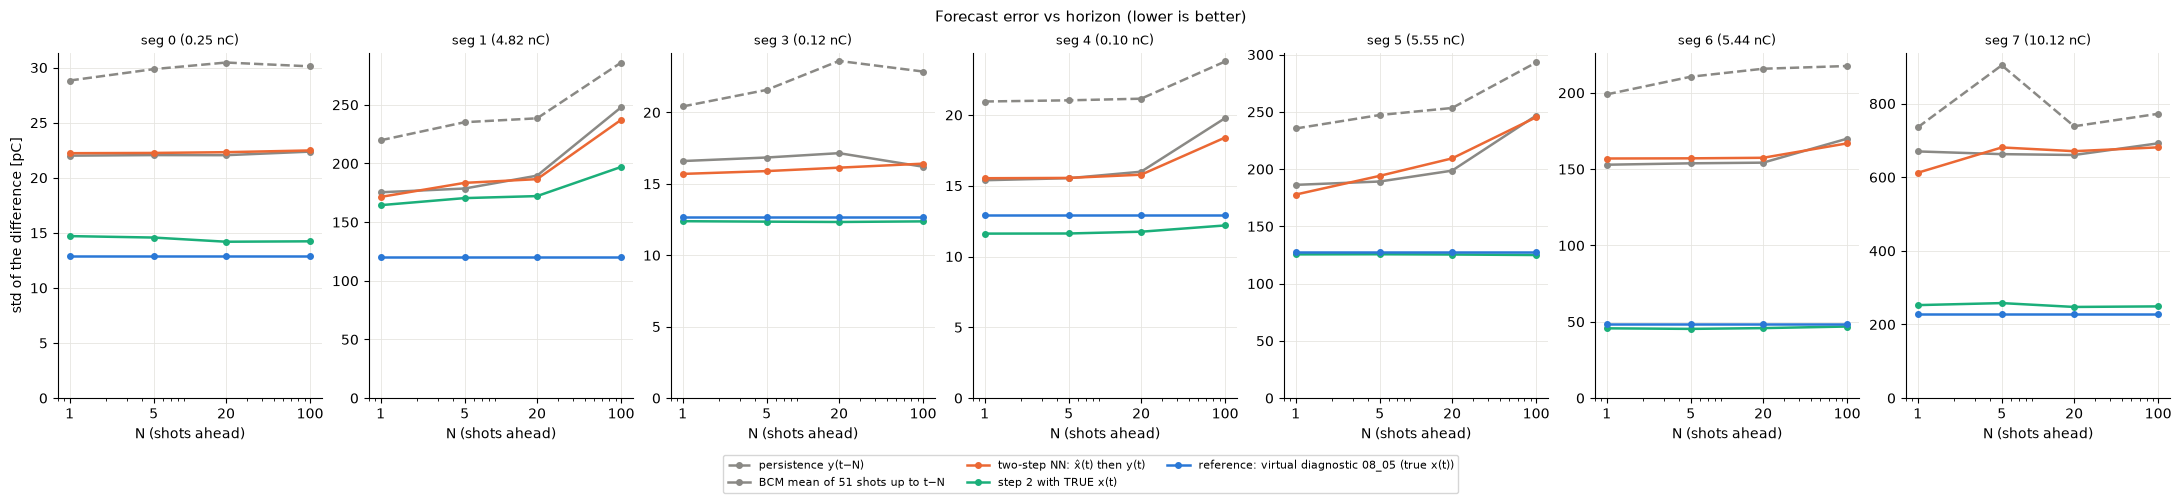

In [5]:
SHOW = {"persistence y(t−N)": "#e6e5e1", "BCM mean of 51 shots up to t−N": "#8a8985",
        "two-step NN: x̂(t) then y(t)": "#eb6834", "step 2 with TRUE x(t)": "#1baf7a",
        "reference: virtual diagnostic 08_05 (true x(t))": "#2a78d6"}
fig, axes = plt.subplots(1, len(SEGS), figsize=(3.1 * len(SEGS), 4.4), layout="constrained")
for ax, k in zip(axes, SEGS):
    for name, color in SHOW.items():
        g = res[(res["segment"] == k) & (res["model"] == name)]
        ax.plot(g["N"], g["std [pC]"], "o-", color=color if name != "persistence y(t−N)" else MUTED,
                ls="--" if name == "persistence y(t−N)" else "-", lw=1.8, ms=4, label=name)
    ax.set(xscale="log", xticks=HORIZONS, xticklabels=HORIZONS, xlabel="N (shots ahead)",
           title=f"seg {k} ({segments[k]['y'][segments[k]['test']].mean():.2f} nC)")
    ax.title.set_fontsize(9)
    ax.set_ylim(bottom=0)
    vd_plots.style(ax)
axes[0].set_ylabel("std of the difference [pC]")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.12))
fig.suptitle("Forecast error vs horizon (lower is better)", fontsize=11)
fig.savefig(OUT / "error_vs_horizon.png", dpi=130, bbox_inches="tight");

### Where is the limit: step 1 (x(t) from the past) or step 2 (y from x)?

- **R² of x̂(t)**: how well step 1 recovers the present features (1 = perfect, 0 = no better than their mean)
- if step 2 with the **true** x(t) is much better than with x̂(t), the bottleneck is step 1: the past does not contain
  the present shot-to-shot state

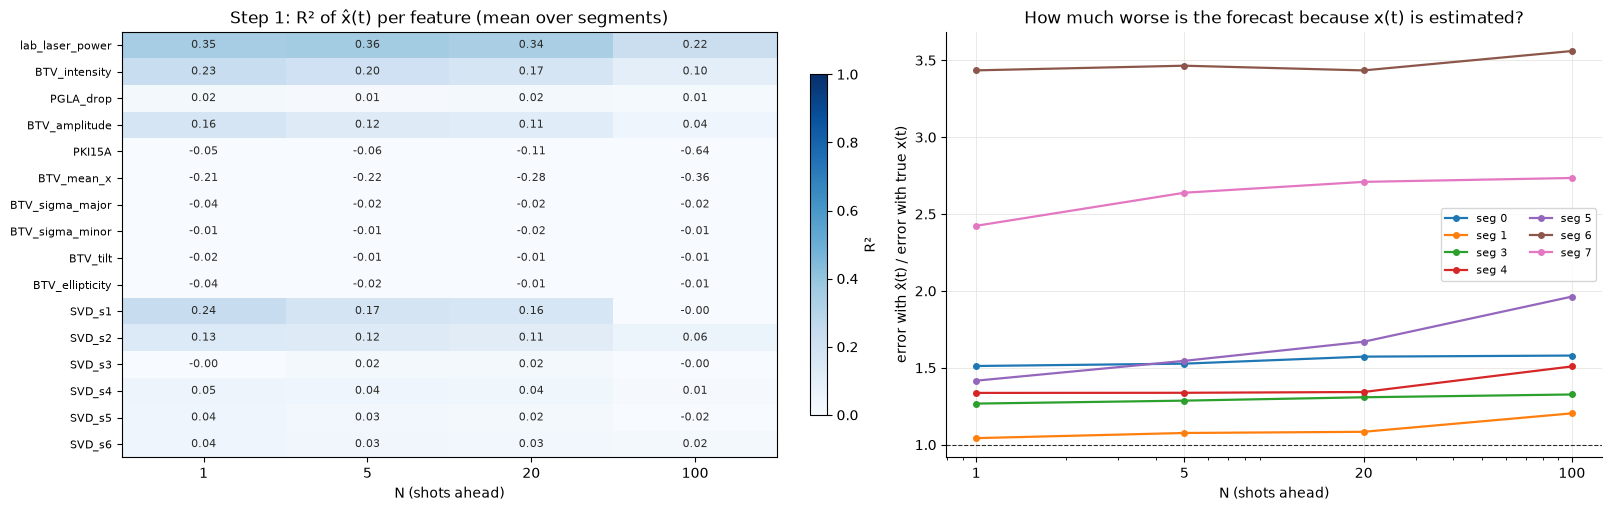

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
r2 = xq.pivot_table(index="feature", columns="N", values="R² of x̂(t)", aggfunc="mean").loc[FEATURES]
im = axes[0].imshow(r2.clip(-0.2, 1), cmap=vd_plots.plt.get_cmap("Blues"), vmin=0, vmax=1, aspect="auto")
for (i, j), v in np.ndenumerate(r2.to_numpy()):
    axes[0].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else INK)
axes[0].set_xticks(range(len(HORIZONS)), HORIZONS)
axes[0].set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
axes[0].set(xlabel="N (shots ahead)", title="Step 1: R² of x̂(t) per feature (mean over segments)")
fig.colorbar(im, ax=axes[0], shrink=0.8, label="R²")

ratio = (res[res["model"] == "two-step NN: x̂(t) then y(t)"].set_index(["segment", "N"])["std [pC]"]
         / res[res["model"] == "step 2 with TRUE x(t)"].set_index(["segment", "N"])["std [pC]"]).unstack("N")
for k in SEGS:
    axes[1].plot(HORIZONS, ratio.loc[k], "o-", lw=1.6, ms=4, label=f"seg {k}")
axes[1].axhline(1, color=INK, lw=0.8, ls="--")
axes[1].set(xscale="log", xticks=HORIZONS, xticklabels=HORIZONS, xlabel="N (shots ahead)",
            ylabel="error with x̂(t) / error with true x(t)", title="How much worse is the forecast because x(t) is estimated?")
axes[1].legend(fontsize=8, ncol=2)
vd_plots.style(axes[1])
fig.savefig(OUT / "step1_vs_step2.png", dpi=130, bbox_inches="tight");

### Slow and fast part of the error (two-step NN vs reference)

**slow** = 51-shot rolling mean of the difference (trend), **fast** = the rest (shot to shot).

In [7]:
parts = res[res["model"].isin(["two-step NN: x̂(t) then y(t)", "BCM mean of 51 shots up to t−N",
                                "reference: virtual diagnostic 08_05 (true x(t))"])]
parts.pivot_table(index=["N", "model"], columns="segment", values=["slow [pC]", "fast [pC]"]).round(1)

fast [pC]               \
segment                                                     0      1     3   
N   model                                                                    
1   BCM mean of 51 shots up to t−N                       21.9  164.9  15.7   
    reference: virtual diagnostic 08_05 (true x(t))      11.9  110.3  12.2   
    two-step NN: x̂(t) then y(t)                         22.1  165.8  15.2   
5   BCM mean of 51 shots up to t−N                       21.9  165.3  15.8   
    reference: virtual diagnostic 08_05 (true x(t))      11.9  110.3  12.2   
    two-step NN: x̂(t) then y(t)                         22.1  174.0  15.3   
20  BCM mean of 51 shots up to t−N                       21.8  164.0  15.7   
    reference: virtual diagnostic 08_05 (true x(t))      11.9  110.3  12.2   
    two-step NN: x̂(t) then y(t)                         22.1  171.2  15.3   
100 BCM mean of 51 shots up to t−N                       21.7  163.4  15.2   
    reference: virtual diagnostic 08_05 (true x(t))      11.9  110.3  12.2   
    two-step NN: x̂(t) then y(t)                         21.8  171.6  15.2   

                                                                         \
segment                                                 4      5      6   
N   model                                                                 
1   BCM mean of 51 shots up to t−N                   15.0  176.3  151.5   
    reference: virtual diagnostic 08_05 (true x(t))  12.5  121.0   33.0   
    two-step NN: x̂(t) then y(t)                     15.2  170.9  156.2   
5   BCM mean of 51 shots up to t−N                   15.0  176.6  152.0   
    reference: virtual diagnostic 08_05 (true x(t))  12.5  121.0   33.0   
    two-step NN: x̂(t) then y(t)                     15.2  182.0  156.4   
20  BCM mean of 51 shots up to t−N                   14.9  175.4  150.0   
    reference: virtual diagnostic 08_05 (true x(t))  12.5  121.0   33.0   
    two-step NN: x̂(t) then y(t)                     15.1  181.1  156.3   
100 BCM mean of 51 shots up to t−N                   15.1  174.9  149.9   
    reference: virtual diagnostic 08_05 (true x(t))  12.5  121.0   33.0   
    two-step NN: x̂(t) then y(t)                     15.0  178.5  157.1   

                                                           slow [pC]         \
segment                                                  7         0      1   
N   model                                                                     
1   BCM mean of 51 shots up to t−N                   651.6       2.8   53.8   
    reference: virtual diagnostic 08_05 (true x(t))  223.2       5.0   48.0   
    two-step NN: x̂(t) then y(t)                     598.0       3.0   41.8   
5   BCM mean of 51 shots up to t−N                   643.6       3.0   61.2   
    reference: virtual diagnostic 08_05 (true x(t))  223.2       5.0   48.0   
    two-step NN: x̂(t) then y(t)                     660.2       3.7   53.9   
20  BCM mean of 51 shots up to t−N                   636.2       3.7   86.8   
    reference: virtual diagnostic 08_05 (true x(t))  223.2       5.0   48.0   
    two-step NN: x̂(t) then y(t)                     637.3       4.0   67.6   
100 BCM mean of 51 shots up to t−N                   638.0       5.7  180.8   
    reference: virtual diagnostic 08_05 (true x(t))  223.2       5.0   48.0   
    two-step NN: x̂(t) then y(t)                     637.6       5.7  157.1   

                                                                             \
segment                                                3     4      5     6   
N   model                                                                     
1   BCM mean of 51 shots up to t−N                   4.2   3.2   52.7  21.9   
    reference: virtual diagnostic 08_05 (true x(t))  3.3   3.0   39.4  35.1   
    two-step NN: x̂(t) then y(t)                     3.8   3.0   47.9  21.4   
5   BCM mean of 51 shots up to t−N                   4.6   3.7   59.7  24.4   
    reference: v

## Shot by shot, N = 1 (first 150 test shots)

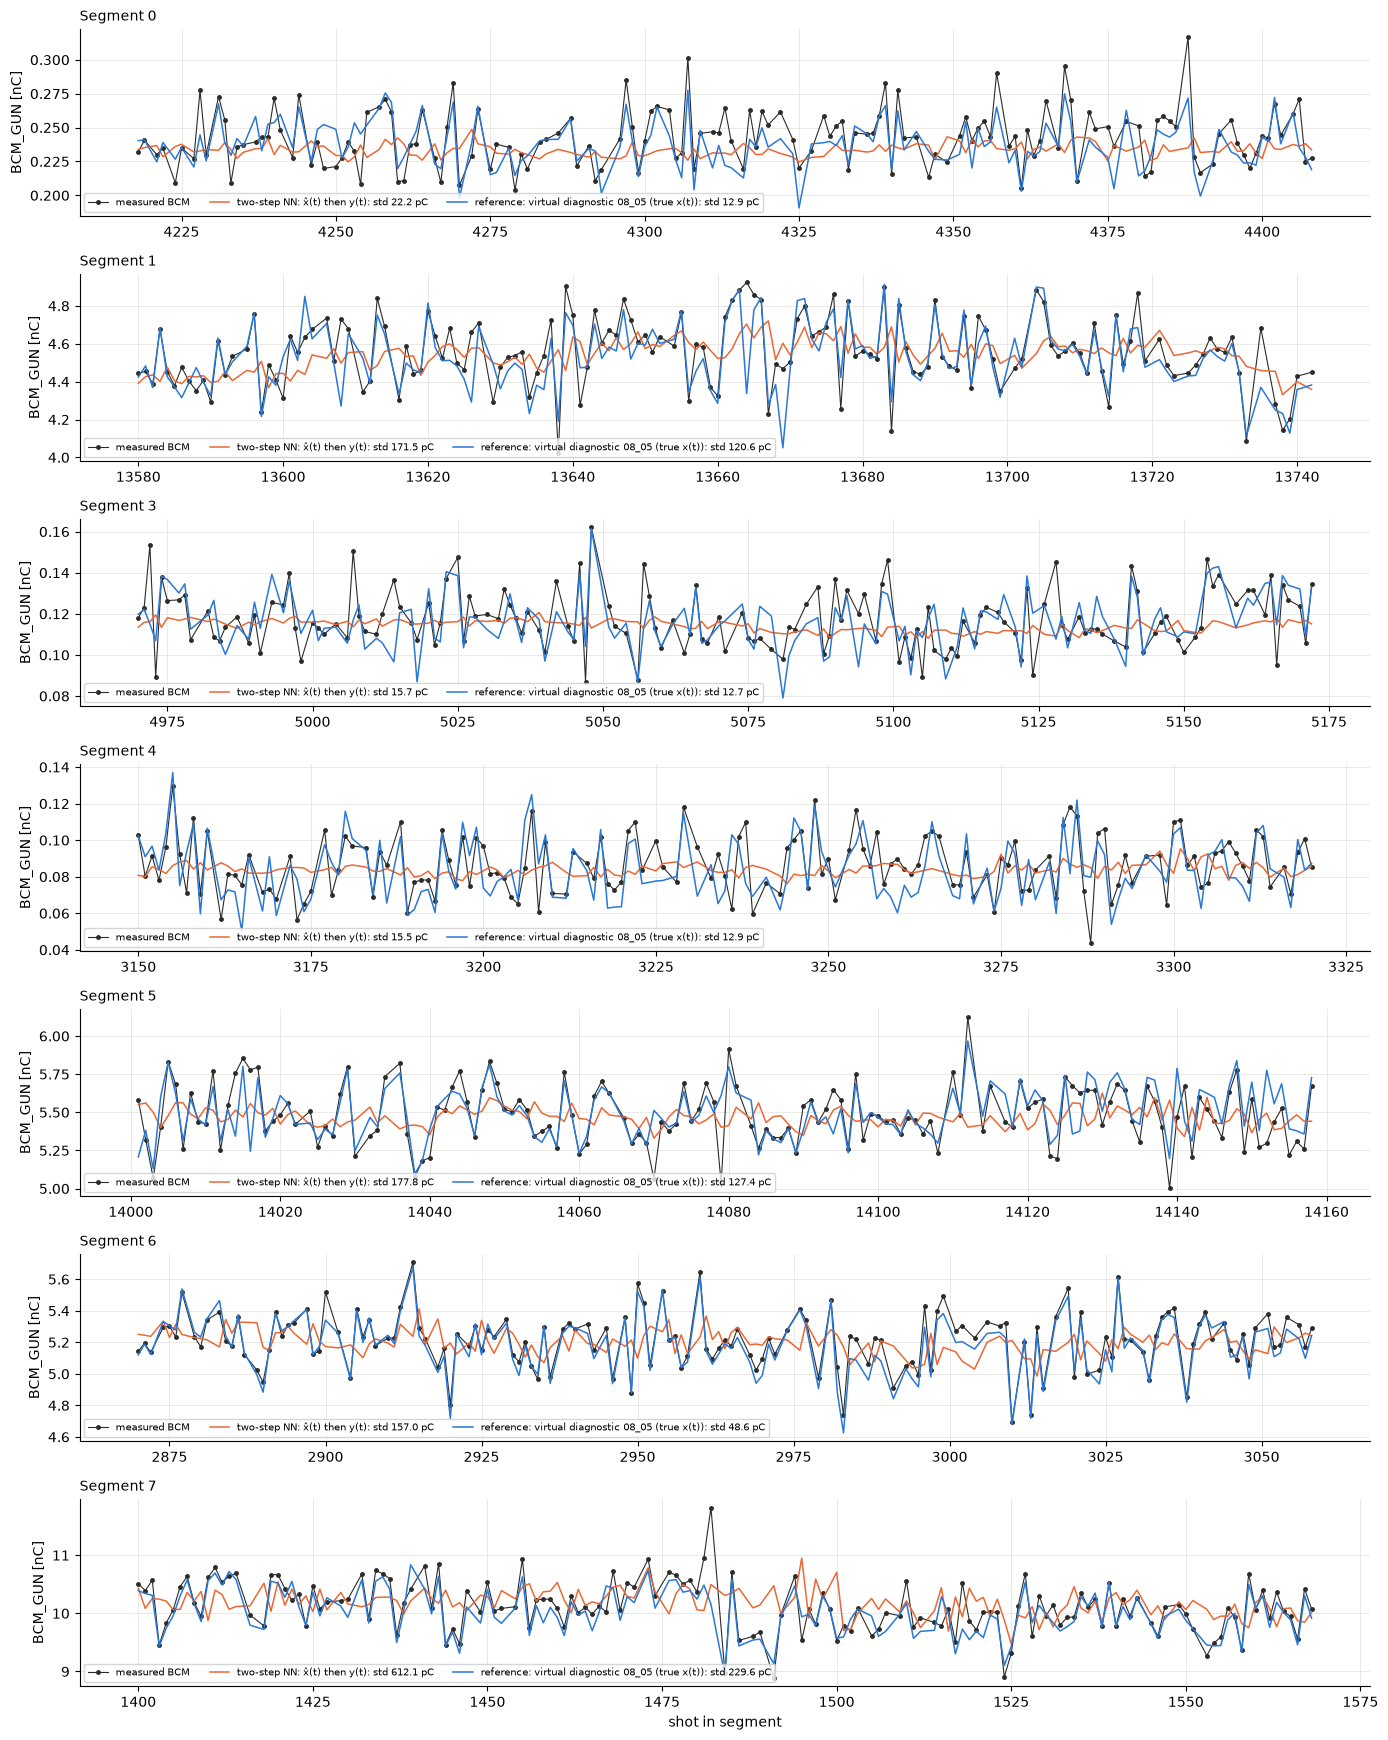

In [8]:
n = 1
fig, axes = plt.subplots(len(SEGS), 1, figsize=(14, 2.5 * len(SEGS)), squeeze=False)
for ax, k in zip(axes[:, 0], SEGS):
    d = preds[(k, n)]
    z = slice(0, 150)
    ax.plot(d["t"][z], d["y"][z], "-o", ms=2.5, lw=0.8, color=INK, label="measured BCM")
    for name, color in [("two-step NN: x̂(t) then y(t)", "#eb6834"), ("reference: virtual diagnostic 08_05 (true x(t))", "#2a78d6")]:
        if name in d:
            e = vm.PC * (d[name] - d["y"]).std()
            ax.plot(d["t"][z], d[name][z], lw=1.1, color=color, label=f"{name}: std {e:.1f} pC")
    ax.set_title(f"Segment {k}", fontsize=10, loc="left")
    ax.set_ylabel("BCM_GUN [nC]")
    ax.legend(fontsize=7, loc="lower left", ncol=3)
    vd_plots.style(ax)
axes[-1, 0].set_xlabel("shot in segment")
fig.tight_layout()
fig.savefig(OUT / "zoom_N1.png", dpi=130, bbox_inches="tight")